# 02 · Data Cleaning & Feature Engineering

Take the *raw* CSVs, quantify and fix data-quality issues, then build the customer-level feature table used for churn modelling.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. Raw data issues

In [2]:
from src.ingestion.etl import load_raw, clean_transactions
raw_tx, raw_cust, raw_prod, raw_inv = load_raw()
issues = pd.Series({
    "duplicate rows": int(raw_tx.duplicated().sum()),
    "negative quantities (returns)": int((raw_tx.quantity < 0).sum()),
    "missing unit_price": int(raw_tx.unit_price.isna().sum()),
    "missing keys": int(raw_tx[["order_date", "customer_id", "product_id"]].isna().any(axis=1).sum()),
})
issues

duplicate rows                   163
negative quantities (returns)    218
missing unit_price               109
missing keys                       0
dtype: int64

## 2. Clean

In [3]:
clean, report = clean_transactions(raw_tx, raw_prod)
print(report)
assert clean.duplicated().sum() == 0 and (clean.quantity > 0).all() and clean.unit_price.notna().all()
clean[["order_id", "order_date", "customer_id", "product_id", "quantity", "unit_price", "revenue"]].head()

{'rows_raw': 54720, 'rows_dropped_missing_keys': 0, 'duplicates_removed': 163, 'missing_prices_imputed': 109, 'returns_or_invalid_removed': 218, 'rows_clean': 54339}


,order_id,order_date,customer_id,product_id,quantity,unit_price,revenue
0,O0000001,2024-01-01,C00009,P030,1,41.09,41.09
1,O0000002,2024-01-01,C00014,P022,1,165.76,165.76
2,O0000003,2024-01-01,C00024,P023,1,79.87,79.87
3,O0000004,2024-01-01,C00046,P022,1,152.71,152.71
4,O0000005,2024-01-01,C00046,P006,4,14.01,56.04


## 3. Customer feature engineering
Features are computed **strictly before** a cutoff date; the label looks at the *next 90 days* (no leakage).

In [4]:
from src.churn.model import build_features, make_training_set, FEATURE_COLUMNS
X, y, cutoff = make_training_set(tx, customers)
print(f"Cutoff: {cutoff.date()} | training customers: {len(X)} | churn rate: {y.mean():.1%} | {len(FEATURE_COLUMNS)} features")
X.head()

Cutoff: 2025-10-03 | training customers: 1118 | churn rate: 25.9% | 20 features


,recency,frequency,monetary,avg_order_value,avg_qty,n_categories,n_stores,tenure_days,avg_gap_days,recency_ratio,orders_30d,orders_90d,orders_prev_90d,order_trend,loyalty_tier_num,age,region_North,region_South,region_East,region_West
customer_id,,,,,,,,,,,,,,,,,,,,
C00001,94,38,3360.53,88.435000,1.578947,5,4,635,16.710526,5.625197,0,0,6,0.142857,0,39,0,0,1,0
C00002,25,26,2767.54,106.443846,1.769231,5,4,487,18.730769,1.334702,1,2,6,0.428571,0,73,1,0,0,0
C00003,1,66,8599.76,130.299394,1.636364,5,4,625,9.469697,0.105600,5,14,17,0.833333,0,49,0,0,0,1
C00004,24,25,4257.60,170.304000,1.880000,5,4,637,25.480000,0.941915,3,5,2,2.000000,0,41,0,1,0,0
C00005,4,41,5259.56,128.281951,1.658537,5,4,616,15.024390,0.266234,4,8,8,1.000000,2,27,0,0,0,1


## 4. Which engineered features separate churners from retained customers?

In [5]:
comp = X.assign(churned=y).groupby("churned")[["recency", "frequency", "monetary", "avg_gap_days",
                                                 "recency_ratio", "orders_90d", "order_trend"]].mean().T
comp.columns = ["retained", "churned"]
comp["ratio churned/retained"] = comp["churned"] / comp["retained"]
comp.round(2)

,retained,churned,ratio churned/retained
recency,19.99,85.23,4.26
frequency,40.74,30.99,0.76
monetary,5099.13,3857.19,0.76
avg_gap_days,19.77,29.97,1.52
recency_ratio,1.08,4.76,4.41
orders_90d,7.25,1.96,0.27
order_trend,1.34,0.75,0.56


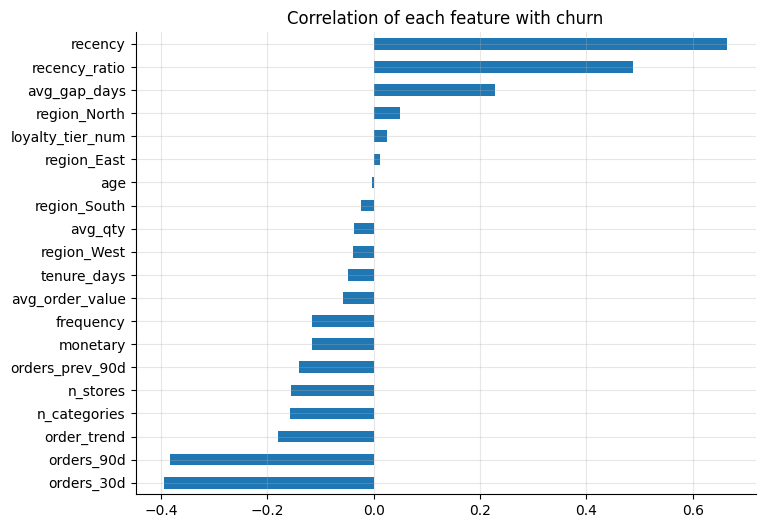

In [6]:
corr = X.assign(churned=y).corr(numeric_only=True)["churned"].drop("churned").sort_values()
corr.plot.barh(title="Correlation of each feature with churn", figsize=(8, 6)); plt.show()